# UniRemington - Cali<br>Facultad de Ingeniería - Línea de Énfasis III: Ciencia de Datos y Machine Learning<br>(ↄ) Diego Fernando Marin, 2026-2

## Datos del Estudiante

**Código**: <br>
**Nombre**:Andres Esteban Vasquez Peña <br>
**Correo**:andres.vasquez.2360@miremington.edu.co

# Taller #2 - Titanic

## 0. Introducción

### ¿Qué vas a hacer en este taller?

Vas a realizar un **análisis exploratorio de datos (EDA) completo** sobre el dataset del Titanic: explorarás los datos, los limpiarás, los transformarás, los visualizarás y, sobre todo, los **interrogarás** para entender qué características de los pasajeros aumentaron o disminuyeron sus probabilidades de sobrevivir. Este taller es la continuación del Taller #1 (Encuesta de TV): allí practicaste con **Pandas** y **Matplotlib**; aquí sumas **Seaborn** (gráficos estadísticos), **NumPy** y una primera prueba de hipótesis con **SciPy**.


### Alcance

Al terminar serás capaz de:

1. Inspeccionar un dataset nuevo y **diagnosticar datos faltantes** con tablas y mapas de calor.
2. Construir **variables nuevas** (*feature engineering*): `Person`, `Alone`, `TCabin`, `TTitulo`.
3. Elegir y construir el gráfico adecuado con Seaborn (conteo, KDE, puntos, regresión, cajas, histogramas).
4. Aplicar y **justificar** estrategias de imputación (moda, promedio por grupo) y reconocer el sesgo que introducen.
5. Codificar variables categóricas como numéricas y leer una **matriz de correlación** con sentido crítico.
6. Distinguir entre **descripción**, **asociación** y **causalidad**, y comunicar con honestidad las limitaciones de tu análisis.


Tu análisis es exitoso si puedes:

- ✅ Explicar cada decisión tomada durante la limpieza de datos.
- ✅ Justificar tus visualizaciones con argumentos claros.
- ✅ Identificar patrones no obvios en los datos.
- ✅ Reconocer las limitaciones de tu análisis.
- ✅ Comunicar tus hallazgos a una audiencia no técnica.
- ✅ Formular hipótesis comprobables a partir de tus observaciones.

## 1. Contexto del problema

Imagina que eres analista de datos en una **empresa de seguros** que investiga patrones históricos de supervivencia en desastres marítimos. La gerencia quiere saber, a partir del caso del Titanic (1912), **qué características de una persona aumentaron o disminuyeron su probabilidad de sobrevivir**, para alimentar modelos de riesgo y protocolos de evacuación.

> **Pregunta central:** ¿Qué factores tuvieron más influencia sobre la supervivencia de los pasajeros del Titanic?

**¿Por qué EDA y no directamente un modelo?** Porque antes de predecir hay que *entender*. Un análisis exploratorio revela errores y vacíos en los datos, genera hipótesis y evita construir modelos sobre supuestos falsos. Además, en este dataset **faltan muchos datos** (edad, cabina) y la forma en que los rellenes **cambia las conclusiones**: ese es el corazón del taller.



### Diccionario de datos

| Variable | Descripción | Tipo esperado |
|---|---|---|
| `PassengerId` | Identificador del pasajero | entero |
| `Survived` | 0 = no sobrevivió, 1 = sobrevivió | entero (categórica binaria) |
| `Pclass` | Clase del tiquete: 1 = alta, 2 = media, 3 = baja | entero (categórica ordinal) |
| `Name` | Nombre completo (incluye el título: Mr, Mrs, Miss…) | texto |
| `Sex` | `male` / `female` | categórica |
| `Age` | Edad en años | decimal (con faltantes) |
| `SibSp` | N.º de hermanos/cónyuge a bordo | entero |
| `Parch` | N.º de padres/hijos a bordo | entero |
| `Ticket` | Número de tiquete | texto |
| `Fare` | Tarifa pagada | decimal |
| `Cabin` | Cabina (la letra indica la cubierta) | texto (muchos faltantes) |
| `Embarked` | Puerto de embarque: C = Cherbourg, Q = Queenstown, S = Southampton | categórica |


## 2. Preparación del entorno

Esta celda ya está completa: es el **ejemplo resuelto** que te muestra el estilo de las siguientes. Ejecútala y lee cada línea.


In [1]:
# 1) Importamos las librerías con sus alias convencionales
import pandas as pd                 # tablas (DataFrame)
import numpy as np                  # cálculo numérico y condiciones vectorizadas
import matplotlib.pyplot as plt     # gráficos base (Seaborn se apoya en él)
import seaborn as sns               # gráficos estadísticos de alto nivel
from scipy import stats             # pruebas estadísticas (la usaremos en la Parte 6)

In [2]:
# 2) Estilo global: todos los gráficos heredan esta configuración
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)   # tamaño por defecto (ancho, alto) en pulgadas
plt.rcParams['axes.titlesize'] = 13

**Nota**: el *dataset* contiene datos de quiénes sobrevivieron, quiénes no sobrevivieron, y quiénes no se sabe. Solo vamos a tener en cuenta los 2 primeros grupos, el 3er grupo lo usamos en el Taller #3.

In [4]:
# 3) Cargamos los datos directamente desde la URL
df = pd.read_csv('https://paste.c-net.org/MarvelJinxed', nrows=891)

> **Teoría — ¿por qué varias librerías?** Cada una resuelve un problema distinto: Pandas organiza y transforma tablas; NumPy ofrece operaciones numéricas rápidas; Matplotlib dibuja; Seaborn dibuja gráficos *estadísticos* con muy pocas líneas (agrupa, calcula intervalos de confianza, aplica temas); SciPy contiene pruebas estadísticas. Se combinan porque se construyeron para ser compatibles entre sí.

> **Tip — si algo sale mal al cargar.** Si obtienes **una sola columna** con todo pegado, el separador no es la coma (en el Taller #1 era `|`). Prueba `pd.read_csv(url, sep='|')` o deja que Pandas lo adivine con `pd.read_csv(url, sep=None, engine='python')`. Si la descarga directa falla, descarga el archivo y cárgalo desde disco.

> **Tip — copia de seguridad.** Muchas transformaciones de este taller **modifican `df`**. Si te equivocas y quieres volver al inicio, vuelve a ejecutar la celda de carga.


## Parte 1 — Primer contacto con los datos (Pasos 1–5)

> **Teoría.** Antes de graficar nada, un analista responde cuatro preguntas: *¿cuánto hay?* (dimensiones), *¿de qué tipo es cada columna?* (tipos), *¿cómo se ve?* (muestra) y *¿qué falta?* (nulos). Los datos faltantes no son un detalle: **pueden sesgar todas tus conclusiones**.


### Paso 1. ¿Cuántos pasajeros (filas) y variables (columnas) hay?

**Lógica:** `shape` devuelve una tupla `(filas, columnas)`.


In [5]:
# Obtén las dimensiones del DataFrame.
# Pista: shape es un ATRIBUTO (no lleva paréntesis).
df.shape


(891, 12)

### Paso 2. ¿Cuáles son las variables, sus nombres y tipos?

**Lógica:** `info()` muestra nombre, **cantidad de valores no nulos** y tipo (`dtype`) de cada columna. Compara el número de no nulos con el total de filas: ahí se descubren los datos faltantes.



In [8]:
# Muestra el resumen estructural del DataFrame.
# Pista: info() es un MÉTODO (lleva paréntesis) e imprime directamente.

df.info(np.dtype)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


> En Pandas 3.x las columnas de texto se muestran como `str`; en versiones anteriores, como `object`. Son equivalentes para este taller.


### Paso 3. Muestra las primeras 10 filas


In [11]:
# Muestra las 10 primeras filas.
# Pista: head(n) recibe el número de filas.

df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


### Paso 4. Estadísticas descriptivas

**Lógica:** `describe()` resume las columnas **numéricas** (conteo, media, desviación, mínimo, cuartiles, máximo). Para las de texto hay que pedirlo aparte.


In [12]:
# 1. Estadísticas descriptivas de las columnas numéricas.
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [13]:
# 2. Estadísticas de las columnas NO numéricas.
#    Pista: df.select_dtypes(exclude='number').describe()
#    (mira 'unique' y 'top': ¿cuántos nombres, tiquetes y cabinas distintos hay?)
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


# hay 891 nombres, 681 tickets, 147 cabinas distintas

### Paso 5. Identificar datos faltantes (con tabla y con mapa de calor)

**Lógica:** `df.isnull()` devuelve una tabla de `True/False` (True = falta el dato). Sumarla da el conteo por columna. Un **heatmap** de esa tabla muestra *dónde* faltan y si hay patrones (por ejemplo, filas a las que les faltan varias cosas a la vez).



In [14]:
# 1. Cuenta los nulos por columna con isnull().sum().
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


<Axes: >

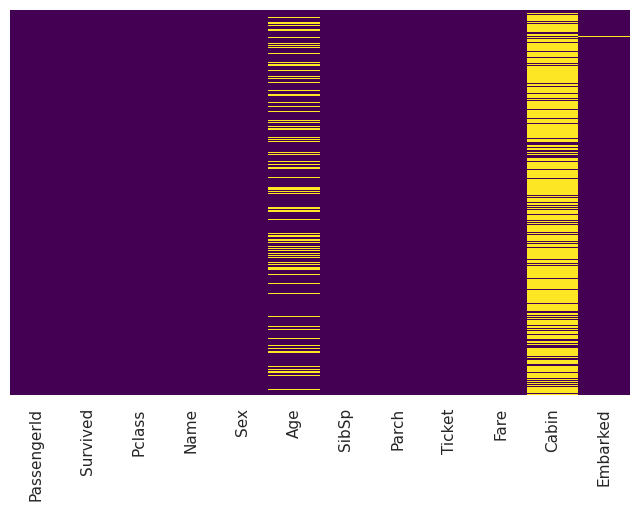

In [16]:
# 2. Dibuja el mapa de calor de df.isnull():
#    sns.heatmap(..., cbar=False, yticklabels=False, cmap='viridis')
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')

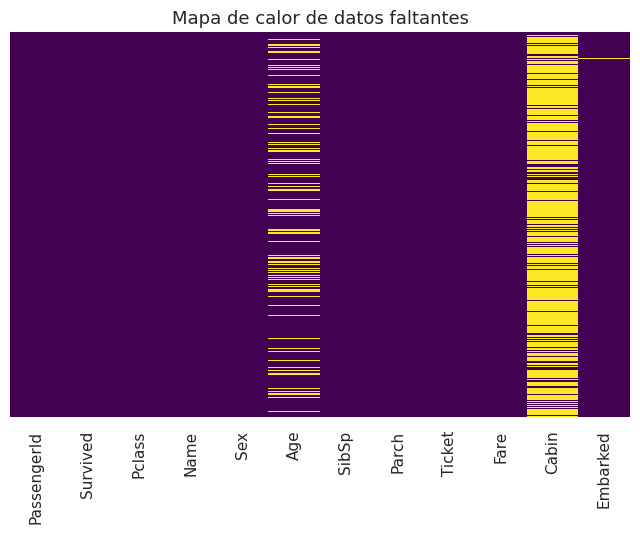

In [18]:
# 3. Añade un título con plt.title(...) y cierra con plt.show().

plt.title('Mapa de calor de datos faltantes')
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.show()

### Evaluación — Parte 1

- **E1.1 (conceptual).** ¿Cuántos pasajeros hay en total? ¿Qué columnas son numéricas y cuáles categóricas? Atención: `Survived` y `Pclass` aparecen como números, pero ¿se comportan como números (¿tiene sentido promediar `Pclass`?)


- **E1.2 (conceptual).** ¿Qué problemas "obvios" observas en los datos (columnas inútiles para el análisis, tipos extraños, faltantes)?


- **E1.3 (código).** Calcula el **porcentaje** de datos faltantes por columna, ordenado de mayor a menor.


In [21]:
# Reto E1.3 — Pista: isnull().mean() devuelve la proporción de nulos por columna;
# multiplica por 100, redondea con round(1) y ordena con sort_values(ascending=False).

df.isnull().mean().round(1).sort_values(ascending=False) * 100

,0
Cabin,80.0
Age,20.0
PassengerId,0.0
Survived,0.0
Name,0.0
Pclass,0.0
SibSp,0.0
Sex,0.0
Parch,0.0
Ticket,0.0


- **E1.4 (conceptual).** ¿Qué columnas tienen más datos faltantes? ¿Podrían sesgar el análisis? Piensa: ¿los faltantes parecen "al azar" o tienen una causa?


- **E1.5 (conceptual — reflexión).** ¿Por qué usamos varias bibliotecas en lugar de una sola? Da un ejemplo de tarea para cada una.


## Parte 2 — Conociendo a los pasajeros (Pasos 6–10)

> **Teoría — dos herramientas nuevas.**
> - `sns.countplot(data=df, x='col', hue='otra')` cuenta filas por categoría; `hue` divide cada barra por una segunda variable.
> - `pd.crosstab(a, b)` produce la **tabla cruzada** (conteos de cada combinación). Con `normalize='columns'` (o `'index'`) los conteos pasan a **proporciones** que suman 1 por columna (o por fila).
>
> Para **comparar grupos de distinto tamaño** usa proporciones, no conteos absolutos.


### Paso 6. Distribución por género y su cruce con la clase


<Axes: xlabel='Sex', ylabel='count'>

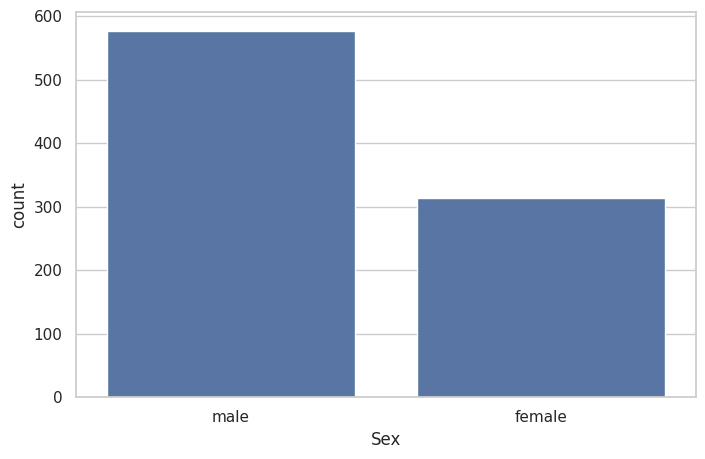

In [22]:
# 1. Gráfico de conteo de 'Sex'.
data=df
x='Sex'
sns.countplot(data=df, x=x)

<Axes: xlabel='Sex', ylabel='count'>

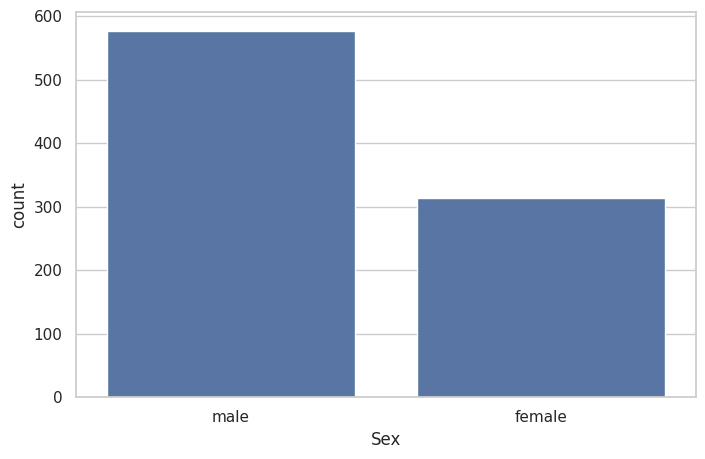

In [23]:
# 2. Gráfico de conteo de 'Sex' con hue='Pclass'.
data=df
x='Sex'
hue='Pclass'
sns.countplot(data=df, x=x)

In [25]:
# 3. Tabla cruzada Sex x Pclass NORMALIZADA POR COLUMNAS:
# Cargamos de nuevo el df original para que no se pierda la información
df = pd.read_csv('https://paste.c-net.org/MarvelJinxed', nrows=891)

tabla_sex_class = pd.crosstab(df['Sex'], df['Pclass'], normalize='columns')
display(tabla_sex_class)

Pclass,1,2,3
Sex,,,
female,0.435185,0.413043,0.293279
male,0.564815,0.586957,0.706721


### Paso 7. Distribución de edades

**Lógica:** un **histograma** divide la variable numérica en intervalos (*bins*) y cuenta cuántos casos caen en cada uno. `Age` tiene nulos: Seaborn los ignora al graficar, pero es bueno hacerlo explícito con `dropna()`.


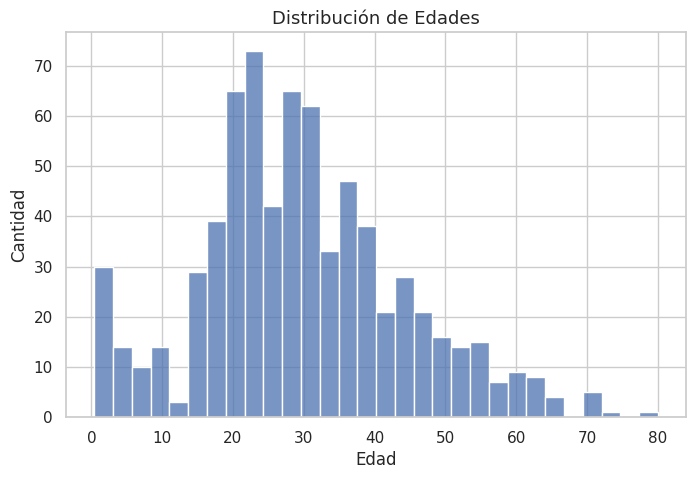

In [26]:
# 1. Histograma de la edad
sns.histplot(df['Age'].dropna(), bins=30, kde=False)
plt.title('Distribución de Edades')
plt.xlabel('Edad')
plt.ylabel('Cantidad')
plt.show()

In [27]:
# 2. Calcula la edad promedio
edad_promedio = df['Age'].mean()
print(f"Edad promedio: {edad_promedio:.2f} años")

Edad promedio: 29.70 años


In [28]:
# 3. Explora: mediana, mínimo y máximo de la edad
print("Mediana:", df['Age'].median())
print("Mínimo:", df['Age'].min())
print("Máximo:", df['Age'].max())

Mediana: 28.0
Mínimo: 0.42
Máximo: 80.0


### Paso 8. Crear la variable `Person` (hombre, mujer o niño)

**Lógica:** `np.where(condición, valor_si_True, valor_si_False)` crea una columna de forma **vectorizada** (sin `for`). Aquí: si `Age < 16` → `'child'`; si no, se conserva el valor de `Sex`.


In [29]:
# Crea df['Person'] con np.where
df['Person'] = np.where(df['Age'] < 16, 'child', df['Sex'])

In [30]:
# Contar cuántos hay de cada tipo
df['Person'].value_counts()

,count
Person,
male,537
female,271
child,83


> **Advertencia — los NaN y las comparaciones.** En Pandas/NumPy, `NaN < 16` da `False`. Por lo tanto, **un pasajero sin edad nunca será `child`**: se queda con su sexo. Es un sesgo silencioso. Lo investigarás en E2.5.


### Paso 9. ¿Cuántos niños viajaban en cada clase?


In [31]:
# Tabla cruzada de 'Pclass' contra 'Person'
pd.crosstab(df['Pclass'], df['Person'])

Person,child,female,male
Pclass,,,
1,6,91,119
2,19,66,99
3,58,114,319


### Paso 10. Gráficos de densidad (KDE) de la edad

> **Teoría — KDE.** La *estimación de densidad por kernel* es un "histograma suavizado": la curva muestra dónde se concentran los valores. Con `hue` se superponen varias curvas. Usa `common_norm=False` para que **cada grupo se normalice por separado** (si no, los grupos grandes "aplastan" a los pequeños).



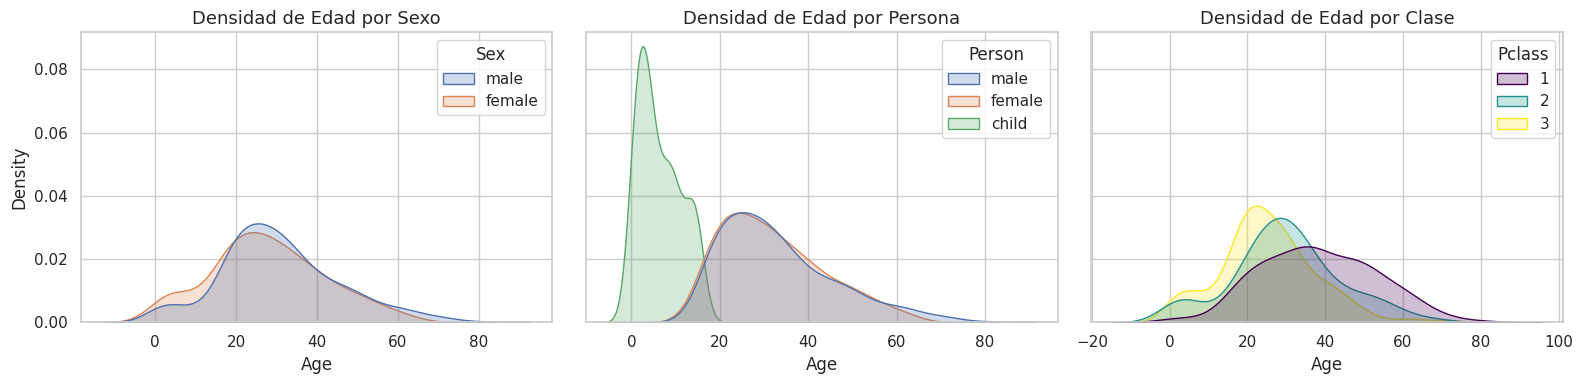

In [32]:
# Gráficos de densidad (KDE) de la edad en 1x3
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

sns.kdeplot(data=df, x='Age', hue='Sex', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('Densidad de Edad por Sexo')

sns.kdeplot(data=df, x='Age', hue='Person', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('Densidad de Edad por Persona')

sns.kdeplot(data=df, x='Age', hue='Pclass', fill=True, common_norm=False, palette='viridis', ax=axes[2])
axes[2].set_title('Densidad de Edad por Clase')

plt.tight_layout()
plt.show()

### Evaluación — Parte 2


- **E2.1 (conceptual).** ¿Hay diferencias en la composición de género entre clases? Apóyate en la tabla normalizada del Paso 6.


Sí hay diferencias claras. En 1 y 2 clase la proporción de hombres y mujeres es casi mitad y mitad

- **E2.2 (código).** Calcula la proporción de menores de 16 años en cada clase (no el conteo).


In [33]:
# Retos E2.2 -> (df['Age'] < 16).groupby(df['Pclass']).mean()
(df['Age'] < 16).groupby(df['Pclass']).mean() * 100

,Age
Pclass,
1,2.777778
2,10.326087
3,11.812627


- **E2.3 (conceptual).** Describe la distribución de edades del Titanic. ¿Cómo era el pasajero "típico"?


El pasajero típico era un joven de entre 20 y 30 años

- **E2.4 (conceptual).** Según los KDE por clase, ¿qué clase tiene pasajeros de más edad? Propón una explicación social (no estadística) para esa diferencia.


 La 1ª clase tiene las curvas de densidad de edad más hacia la derecha, La explicación social es lógica: para tener el dinero y pagar un boleto de primera clase en 1912, necesitabas años de carrera, herencias o ser un empresario consolidado

- **E2.5 (código + conceptual).** ¿Cuántos pasajeros **sin edad** quedaron clasificados como `male` o `female` en `Person`? ¿Por qué eso puede subestimar el número de niños?


In [34]:
# Retos E2.5-> filtra df[df['Age'].isnull()] y cuenta sus valores de 'Person'
df[df['Age'].isnull()]['Person'].value_counts()

,count
Person,
male,124
female,53


177 pasajeros que no tenían edad registrada se quedaron clasificados directamente como hombres con 124 o mujeres con 53. Esto subestima a los niños porque es muy probable que entre esos 177 huérfanos de datos hubiera varios niños que contamos como adultos.

## Parte 3 — Ubicación, embarque y composición familiar (Pasos 11–15)

> **Teoría — extraer información de texto.** Con una Serie de texto, el accesor `.str` aplica operaciones a cada elemento a la vez: `serie.str[0]` toma el primer carácter. En `Cabin` (por ejemplo `'C85'`) la primera letra indica la **cubierta**.



### Paso 11. Extraer la cubierta de la cabina


In [35]:
# 1. Guarda en 'cabinas' las cabinas NO nulas: df['Cabin'].dropna()
cabinas = df['Cabin'].dropna()

In [36]:
# 2. Crea 'cubierta' tomando la primera letra de cada cabina (.str[0])
cubierta = cabinas.str[0]

In [37]:
# 3. Muestra los conteos por cubierta con value_counts()
cubierta.value_counts()

,count
Cabin,
C,59
B,47
D,33
E,32
A,15
F,13
G,4
T,1


### Paso 12. Gráfico de conteo por cubierta (con depuración de anómalos)


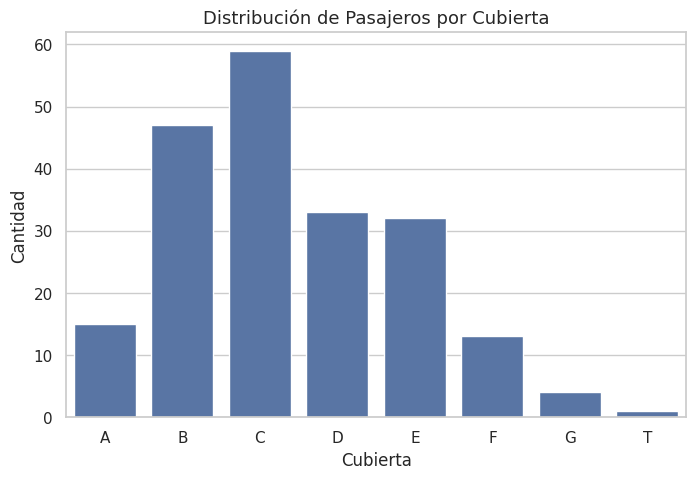

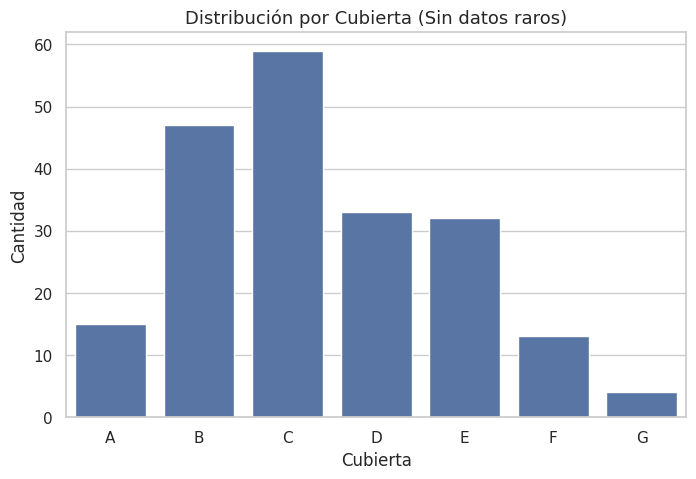

In [38]:
# 1. Dibuja el gráfico de conteo ordenado
sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Distribución de Pasajeros por Cubierta')
plt.xlabel('Cubierta')
plt.ylabel('Cantidad')
plt.show()

# 2. Si hay un dato raro como 'T' (que solo tiene 1), lo limpiamos y volvemos a graficar
cubierta = cubierta[cubierta != 'T']

plt.figure()
sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Distribución por Cubierta (Sin datos raros)')
plt.xlabel('Cubierta')
plt.ylabel('Cantidad')
plt.show()

### Paso 13. Puerto de embarque y clase


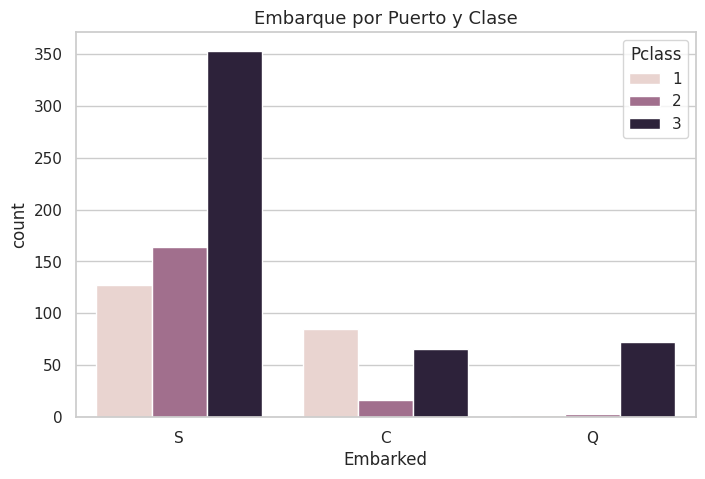

Pclass,1,2,3
Embarked,,,
C,0.505952,0.101190,0.392857
Q,0.025974,0.038961,0.935065
S,0.197205,0.254658,0.548137


In [39]:
# 1. Gráfico de conteo de 'Embarked' con hue='Pclass'
sns.countplot(data=df, x='Embarked', hue='Pclass')
plt.title('Embarque por Puerto y Clase')
plt.show()

# 2. Tabla cruzada normalizada por filas (¿de qué clase venían en cada puerto?)
tabla_puerto = pd.crosstab(df['Embarked'], df['Pclass'], normalize='index')
display(tabla_puerto)

### Paso 14. Crear la variable `Alone` (solo vs. con familia)

**Lógica:** `SibSp + Parch` es el número de familiares a bordo. Si es 0, viaja solo.


In [40]:
# 1. Crea df['Familia'] = df['SibSp'] + df['Parch']
df['Familia'] = df['SibSp'] + df['Parch']

In [41]:
# 2. Crea df['Alone'] con np.where
df['Alone'] = np.where(df['Familia'] > 0, 'with Family', 'Alone')

In [42]:
# 3. Proporción de cada categoría
df['Alone'].value_counts(normalize=True) * 100

,proportion
Alone,
Alone,60.26936
with Family,39.73064


### Paso 15. Visualizar la distribución de `Alone`


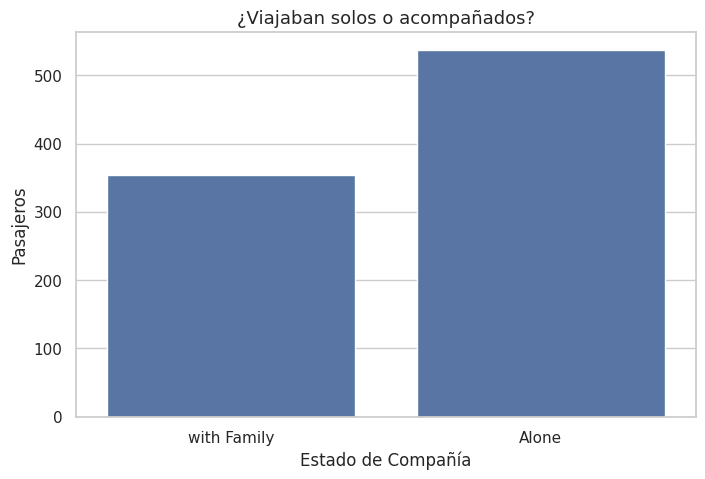

In [43]:
# Gráfico de conteo de 'Alone'
sns.countplot(data=df, x='Alone')
plt.title('¿Viajaban solos o acompañados?')
plt.xlabel('Estado de Compañía')
plt.ylabel('Pasajeros')
plt.show()

### Evaluación — Parte 3


- **E3.1 (código).** ¿Qué porcentaje de pasajeros tiene información de cabina?


In [44]:
# Reto E3.1 -> Porcentaje de cabinas conocidas
porcentaje_cabina = df['Cabin'].notna().mean() * 100
print(f"Porcentaje de pasajeros con cabina registrada: {porcentaje_cabina:.2f}%")

Porcentaje de pasajeros con cabina registrada: 22.90%


- **E3.2 (conceptual).** ¿Qué cubiertas eran las más ocupadas? ¿Qué implicaciones tiene que falten tantos datos de cabina? ¿Esa "ocupación" refleja de verdad el barco?


Las cubiertas C, B y D eran las más llenas de datos. El problemón es que falta datos de cabina. Así que esa ocupación de cubiertas no refleja el barco real la gente de 1ª clase sí aparece ahí, mientras que la gente de 3ª clase casi no tiene registros y se quedó por fuera del mapa.

- **E3.3 (conceptual).** En el Paso 12, ¿era correcto eliminar la cubierta anómala? Da un argumento a favor y uno en contra.


A favor: 'T' solo tenía un pasajero y distorsionaba la gráfica de las cubiertas reales del barco.
En contra: Eliminar datos porque son poquitos es sesgar la base de datos; ese único pasajero existió y estuvo en esa sección del barco.

- **E3.4 (conceptual).** ¿Existe relación entre el puerto de embarque y la clase? Describe qué puerto se parece más a "tercera clase" y cuál a "primera".


Totalmente de acuerdo. En Queenstown casi el 92% de los que subieron eran de 3ª clase los que trabajan, mientras que en Cherbourg casi el 50% de la gente era de 1ª clase los que tenian dinero.

- **E3.5 (conceptual).** ¿Qué proporción viajaba sola? Formula una **hipótesis** (con su razón) sobre si viajar en familia afectó la supervivencia. La verificarás en la Parte 9.


El 60.2% de la gente viajaba sola. Mi hipótesis es que viajar con familia aumentó el chance de sobrevivir porque se habrán ayudado entre ellos para buscar botes salvavidas, o les dieron prioridad por viajar en grupo familiar.

### Paso 16. Panorama general


In [45]:
# 1. Crea df['Survivor'] mapeando 0 -> 'No' y 1 -> 'Yes' con .map
df['Survivor'] = df['Survived'].map({0: 'No', 1: 'Yes'})

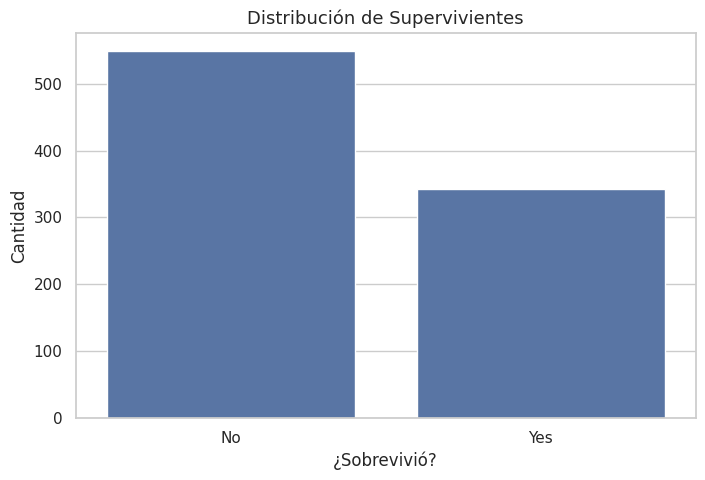

In [46]:
# 2. Gráfico de conteo de 'Survivor'
sns.countplot(data=df, x='Survivor')
plt.title('Distribución de Supervivientes')
plt.xlabel('¿Sobrevivió?')
plt.ylabel('Cantidad')
plt.show()

In [47]:
# 3. Calcula la tasa general de supervivencia
tasa_supervivencia = df['Survived'].mean() * 100
print(f"Tasa general de supervivencia: {tasa_supervivencia:.2f}%")

Tasa general de supervivencia: 38.38%


### Paso 17. Supervivencia por clase


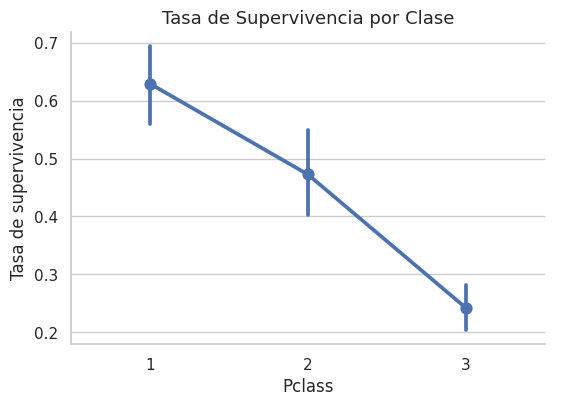

In [48]:
# Gráfico de puntos de supervivencia por clase
sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
plt.title('Tasa de Supervivencia por Clase')
plt.ylabel('Tasa de supervivencia')
plt.show()

### Paso 18. Supervivencia por clase y tipo de persona


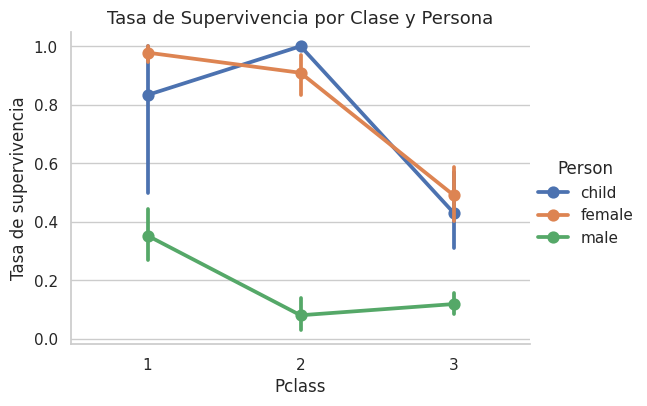

In [49]:
# Supervivencia por clase y tipo de persona
sns.catplot(data=df, x='Pclass', y='Survived', hue='Person', hue_order=['child', 'female', 'male'], kind='point', height=4, aspect=1.4)
plt.title('Tasa de Supervivencia por Clase y Persona')
plt.ylabel('Tasa de supervivencia')
plt.show()

### Paso 19. Edad y supervivencia

> **Teoría — `lmplot`.** Dibuja una **recta de regresión** (con banda de confianza) de y contra x. Con `y` binaria (0/1) la recta es solo una *aproximación visual* de la tendencia. El parámetro `x_bins` agrupa la edad en intervalos y dibuja la **tasa media por intervalo**, lo cual es mucho más legible.


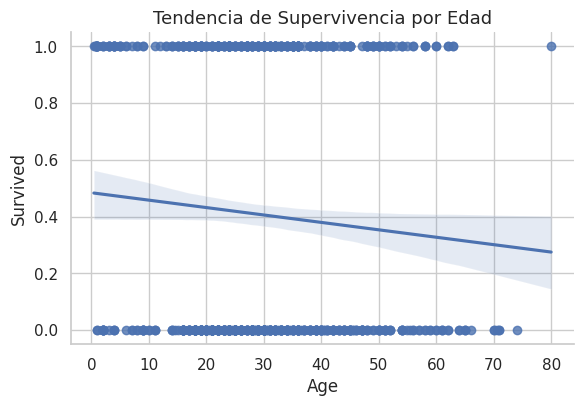

In [50]:
# 1. lmplot básico de edad vs supervivencia
sns.lmplot(data=df, x='Age', y='Survived', height=4, aspect=1.5)
plt.title('Tendencia de Supervivencia por Edad')
plt.show()

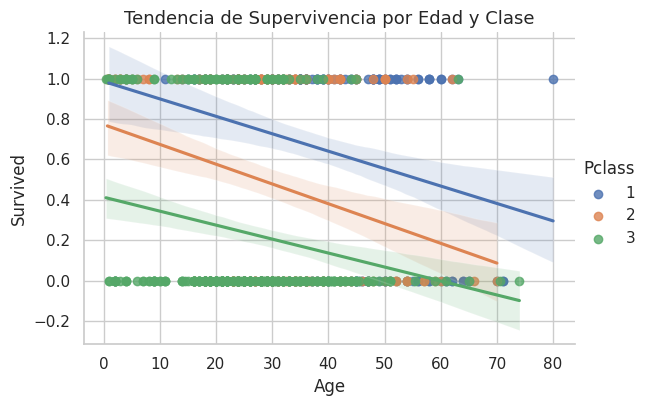

In [51]:
# 2. lmplot añadiendo hue='Pclass'
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass', height=4, aspect=1.5)
plt.title('Tendencia de Supervivencia por Edad y Clase')
plt.show()

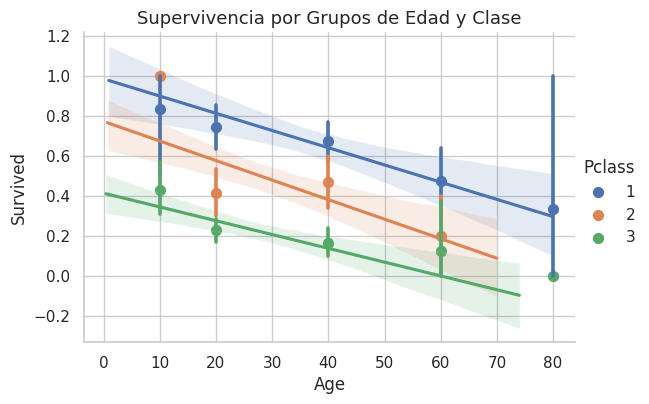

In [52]:
# 3. Bins generacionales con hue='Pclass'
generaciones = [10, 20, 40, 60, 80]
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass', x_bins=generaciones, height=4, aspect=1.5)
plt.title('Supervivencia por Grupos de Edad y Clase')
plt.show()

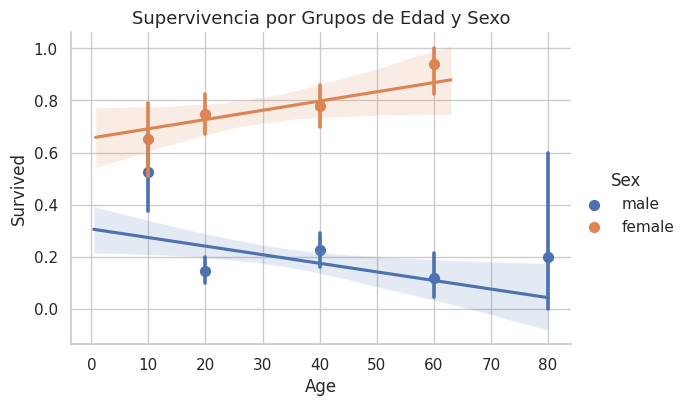

In [53]:
# 4. Bins generacionales con hue='Sex'
generaciones = [10, 20, 40, 60, 80]
sns.lmplot(data=df, x='Age', y='Survived', hue='Sex', x_bins=generaciones, height=4, aspect=1.5)
plt.title('Supervivencia por Grupos de Edad y Sexo')
plt.show()

### Paso 20. Relación tarifa-edad


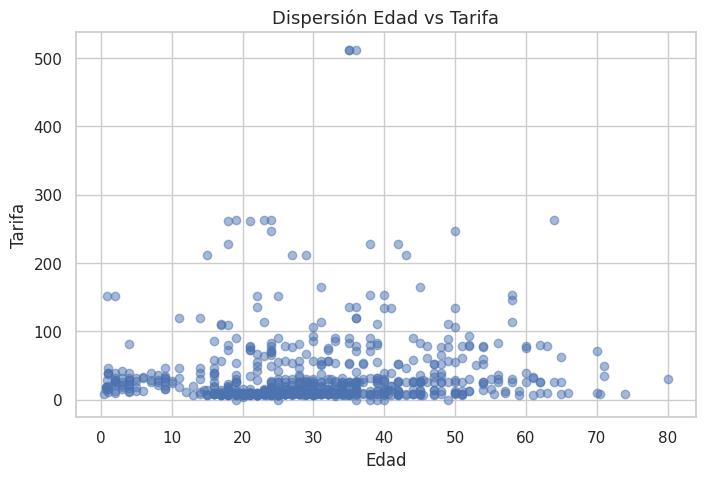

In [54]:
# 1. Dispersión simple de edad y tarifa
plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.title('Dispersión Edad vs Tarifa')
plt.xlabel('Edad')
plt.ylabel('Tarifa')
plt.show()

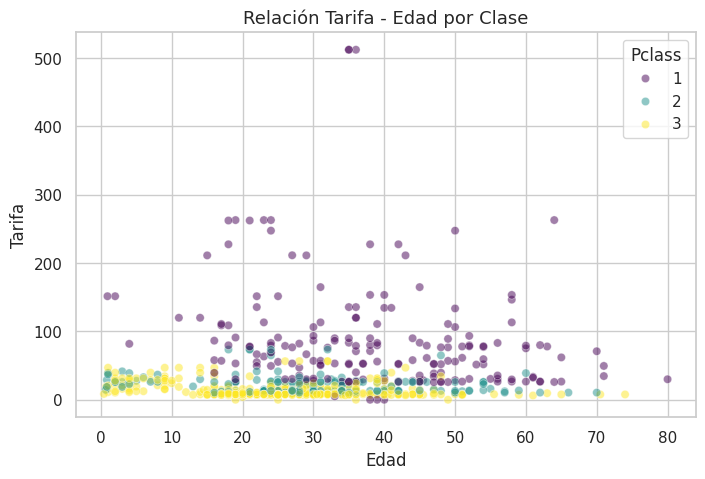

In [55]:
# 2. Dispersión coloreada por clase
sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.5, palette='viridis')
plt.title('Relación Tarifa - Edad por Clase')
plt.xlabel('Edad')
plt.ylabel('Tarifa')
plt.show()

### Evaluación — Parte 4


- **E4.1 (conceptual).** ¿Cuál fue la tasa general de supervivencia? ¿Qué clase tuvo mejor tasa y por qué crees que ocurrió?


La tasa general de supervivencia fue de solo el 38.38%. Los pasajeros de 1ª clase tuvieron la mejor tasa de supervivencia, porque estaban físicamente más cerca de la cubierta de botes y lógicamente el dinero y la influencia social les dieron prioridad.

- **E4.2 (código).** Construye una **tabla** con la tasa de supervivencia por `Pclass` (filas) y `Person` (columnas). ¿Se cumplió "mujeres y niños primero"? ¿Hay excepciones?


In [56]:
# Reto E4.2 -> Tabla pivote de supervivencia
df.pivot_table(values='Survived', index='Pclass', columns='Person', aggfunc='mean')

Person,child,female,male
Pclass,,,
1,0.833333,0.978022,0.352941
2,1.000000,0.909091,0.080808
3,0.431034,0.491228,0.119122


In [57]:
# Reto extra: tabla pivote con media y conteo
df.pivot_table(values='Survived', index='Pclass', columns='Person', aggfunc=['mean', 'count'])

mean                     count            
Person     child    female      male child female male
Pclass                                                
1       0.833333  0.978022  0.352941     6     91  119
2       1.000000  0.909091  0.080808    19     66   99
3       0.431034  0.491228  0.119122    58    114  319

Sí se cumplió totalmente

- **E4.4 (conceptual).** En el Paso 19, ¿existe una tendencia entre edad y supervivencia? ¿Cambia por clase? ¿Y por género? ¿Qué cambia al variar los *bins*?


 a mayor edad, menor supervivencia. Pero al ver por género, se nota que a los hombres les iba peor entre más viejos, mientras que a las mujeres les iba bien sin importar la edad. Agrupar en bins ayuda muchísimo a quitar el ruido visual de cada puntito y ver tendencias claras por grupos.

- **E4.5 (conceptual).** En el Paso 18, el intervalo de confianza de los niños de primera clase es muy ancho. ¿Por qué? ¿Qué cuidado implica para interpretar ese punto?


El intervalo de confianza es gigante porque había muy poquitos niños en 1ª clase. Al tener una muestra tan chiquita, cualquier cálculo estadístico es muy inestable, por lo que hay que interpretar ese porcentaje con mucho cuidado porque no es un dato robusto.

- **E4.6 (conceptual).** ¿Qué revela el gráfico tarifa-edad coloreado por clase sobre la relación entre tarifa, edad y clase?


Revela que las tarifas más altas están reservadas casi exclusivamente para la 1ª clase

## Parte 5 — Limpieza y preparación de datos (Pasos 21–26)

> **Teoría — tres decisiones de limpieza.** Un dato faltante puede (a) eliminarse, (b) rellenarse con un valor "razonable" (*imputación*) o (c) conservarse como una categoría propia ("desconocido"). **Ninguna opción es neutral:** cada una cambia lo que los datos dicen. Documenta siempre qué hiciste y por qué.
>
> **Teoría — codificación.** Los modelos y las correlaciones necesitan números. Convertir categorías a números con `.map({...})` crea columnas nuevas (con prefijo `N`). Cuidado: **un número impone un orden** que quizá no existe (¿es "Q = 2" mayor que "S = 0"?).


### Paso 21. Datos faltantes en `Embarked`


In [58]:
# 1. ¿Cuántos valores faltan en 'Embarked'?
print("Valores faltantes en Embarked:", df['Embarked'].isnull().sum())

Valores faltantes en Embarked: 2


In [59]:
# 2. Calcula la categoría más frecuente
moda_embarked = df['Embarked'].mode()[0]
print("Puerto más común (moda):", moda_embarked)

Puerto más común (moda): S


In [60]:
# 3. Rellena los faltantes con esa moda
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [61]:
# 4. Crea df['NEmbarked'] mapeando S -> 0, C -> 1, Q -> 2
df['NEmbarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

### Paso 22. Datos faltantes en `Age`

**Lógica:** en lugar de rellenar con el promedio global, rellenamos con el **promedio de su grupo** (género). Se calcula una tabla `promedio por género` y se "traduce" cada pasajero a su promedio con `.map`.


In [62]:
# 1. Calcula la edad promedio por género
promedios = df.groupby('Sex')['Age'].mean()
print(promedios)

Sex
female    27.915709
male      30.726645
Name: Age, dtype: float64


In [63]:
# 2. Rellena los nulos de 'Age'
df['Age'] = df['Age'].fillna(df['Sex'].map(promedios))

In [64]:
# 3. Verifica que no queden nulos en 'Age'
print("Nulos en Age:", df['Age'].isnull().sum())

Nulos en Age: 0


In [65]:
# 4. Guarda la desviación estándar de 'Age' ANTES de rellenar para compararla
# Nota: como ya rellenamos en el paso anterior, calculamos con la copia original
df_temp = pd.read_csv('https://paste.c-net.org/MarvelJinxed', nrows=891)
std_antes = df_temp['Age'].std()
std_despues = df['Age'].std()
print(f"Desviación antes: {std_antes:.2f} | Desviación después: {std_despues:.2f}")

Desviación antes: 14.53 | Desviación después: 13.01


### Paso 23. Convertir `Sex` a número


In [66]:
# Crea df['NSex'] mapeando female -> 0 y male -> 1
df['NSex'] = df['Sex'].map({'female': 0, 'male': 1})

### Paso 24. Tratamiento de `Cabin`


In [67]:
# 1. Rellena los nulos de 'Cabin' con 'X'
df['Cabin'] = df['Cabin'].fillna('X')

In [68]:
# 2. Crea df['TCabin'] con la primera letra de la cabina
df['TCabin'] = df['Cabin'].str[0]

In [69]:
# 3. Cuenta los pasajeros por cubierta
df['TCabin'].value_counts()

,count
TCabin,
X,687
C,59
B,47
D,33
E,32
A,15
F,13
G,4
T,1


In [70]:
# 4. Crea df['NCabin'] asignando un número a cada cubierta
mapa_cabinas = {letra: i for i, letra in enumerate(sorted(df['TCabin'].unique()))}
df['NCabin'] = df['TCabin'].map(mapa_cabinas)
print(mapa_cabinas)

{'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'T': 7, 'X': 8}


### Paso 25. Extracción de títulos del nombre

> **Teoría — expresiones regulares (regex).** Los nombres tienen la forma `"Braund, Mr. Owen Harris"`. El título está entre la coma y el punto. El patrón `r',\s*([^.]+)\.'` significa: una coma, espacios opcionales (`\s*`), y captura (`( )`) todo lo que no sea un punto (`[^.]+`), hasta el punto. `str.extract(patron, expand=False)` devuelve la parte capturada.


In [71]:
# 1. Crea df['TTitulo'] extrayendo el título con regex
df['TTitulo'] = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()

In [72]:
# 2. Analiza la frecuencia de cada título
df['TTitulo'].value_counts()

,count
TTitulo,
Mr,517
Miss,182
Mrs,125
Master,40
Dr,7
Rev,6
Col,2
Mlle,2
Major,2


In [73]:
# 3. Tabla cruzada de título vs género
pd.crosstab(df['TTitulo'], df['Sex'])

Sex,female,male
TTitulo,,
Capt,0,1
Col,0,2
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40
Miss,182,0


### Paso 26. Consolidar títulos

**Lógica:** los títulos raros dejan grupos de 1 o 2 personas: inútiles para estadística. Se agrupan en categorías más generales con `replace` (un diccionario) y `where/isin` (todo lo que no esté en la lista principal pasa a `'Otro'`).



In [74]:
# 1. Reemplaza títulos raros con categorías conocidas
reemplazos = {
    'Mlle': 'Miss', 'Ms': 'Miss', 'Lady': 'Miss',
    'Mme': 'Mrs', 'the Countess': 'Mrs', 'Dona': 'Mrs',
    'Master': 'Mr'
}
df['TTitulo'] = df['TTitulo'].replace(reemplazos)

In [75]:
# 2. Todo título que NO esté en ['Mr', 'Mrs', 'Miss'] pasa a 'Otro'
df['TTitulo'] = df['TTitulo'].where(df['TTitulo'].isin(['Mr', 'Mrs', 'Miss']), 'Otro')

In [76]:
# 3. Revisa los conteos finales
df['TTitulo'].value_counts()

,count
TTitulo,
Mr,557
Miss,186
Mrs,127
Otro,21


In [77]:
# 4. Crea df['NTitulo'] mapeando Mr -> 0, Mrs -> 1, Miss -> 2, Otro -> 3
df['NTitulo'] = df['TTitulo'].map({'Mr': 0, 'Mrs': 1, 'Miss': 2, 'Otro': 3})

### Evaluación — Parte 5


- **E5.1 (conceptual).** ¿Es apropiado rellenar `Embarked` con el valor más común? Menciona **dos alternativas** y su costo.


si es súper rápido pero tiene un costo: asume que todo el mundo se subió en el mismo sitio.

1. Buscar con el nombre de pila de esos 2 pasajeros para saber dónde abordaron. su costo es un proceso manual lento.
2.  Ver qué puerto cobraba tarifas similares para esa clase. su costo requiere hacer más código y lógica estadística.

- **E5.2 (código).** Rellenar la edad por género es una opción. Prueba otra: la **mediana por `Pclass` y `Sex`**. Compara los dos resultados para el mismo pasajero. (Pista: necesitas recargar los datos originales para no usar edades ya rellenadas.)


In [78]:
# Reto E5.2 -> Rellenamos usando la mediana por Clase y Sexo
df_temp2 = pd.read_csv('https://paste.c-net.org/MarvelJinxed', nrows=891)
mediana_grupos = df_temp2.groupby(['Pclass', 'Sex'])['Age'].transform('median')
edad_mediana = df_temp2['Age'].fillna(mediana_grupos)

print("Ejemplo de edad rellenada con mediana por grupo:")
print(edad_mediana.head(10))

Ejemplo de edad rellenada con mediana por grupo:
0    22.0
1    38.0
2    26.0
3    35.0
4    35.0
5    25.0
6    54.0
7     2.0
8    27.0
9    14.0
Name: Age, dtype: float64


- **E5.3 (código + conceptual).** Compara la desviación estándar de `Age` antes y después de rellenar con promedios. ¿Qué pasó con la variabilidad? ¿Qué sesgo introduce el método?


In [79]:
# Comparamos la desviación estándar
std_antes = pd.read_csv('https://paste.c-net.org/MarvelJinxed', nrows=891)['Age'].std()
std_despues = df['Age'].std()
print(f"Desviación estándar ANTES: {std_antes:.4f}")
print(f"Desviación estándar DESPUÉS: {std_despues:.4f}")
print("Efecto: La variabilidad bajó. El sesgo es que artificialmente creamos un montón de pasajeros con la edad exacta del promedio, eliminando las diferencias naturales.")

Desviación estándar ANTES: 14.5265
Desviación estándar DESPUÉS: 13.0149
Efecto: La variabilidad bajó. El sesgo es que artificialmente creamos un montón de pasajeros con la edad exacta del promedio, eliminando las diferencias naturales.


- **E5.4 (código + ética).** ¿Deberíamos eliminar `Cabin` por tener tantos faltantes? Calcula la tasa de supervivencia de quienes **sí** tienen cabina frente a quienes **no** (`TCabin != 'X'`) y argumenta si "tener cabina registrada" es información en sí misma.


In [81]:
# Reto E5.4 -> Supervivencia de quienes tienen cabina ('Cabin' != 'X') frente a quienes no
df.groupby(df['TCabin'] != 'X')['Survived'].agg(['mean', 'count'])

,mean,count
TCabin,,
False,0.299854,687
True,0.666667,204


- **E5.5 (conceptual).** La consolidación `Master → Mr` junta a niños varones con hombres adultos. ¿Qué información se pierde? ¿Y es discutible que `Lady → Miss`?


Al meter a Master en Mr perdemos por completo la información de que eran niños varones pequeños, lo cual altera las estadísticas de supervivencia de menores de edad. Por otra parte, meter a Lady como Miss es bastante discutible en la época, ya que 'Lady' indica un estatus social de nobleza muy alto que no necesariamente equivale a una mujer soltera joven.

- **E5.6 (conceptual — sociológica).** ¿Qué nos revelan los títulos sobre la estructura social de la época?


Nos revelan que la sociedad eduardiana de 1912 estaba absurdamente jerarquizada. El estatus social, la nobleza y los títulos de respeto pesaban tanto que se ponían por encima de la identidad de la persona, incluso en la lista oficial de pasajeros de un barco.

- **E5.7 (conceptual).** `NEmbarked`, `NCabin` y `NTitulo` asignan números a categorías **sin orden natural**. ¿Qué riesgo tiene eso al calcular correlaciones o entrenar un modelo? ¿Qué técnica lo evita? (Pista: *one-hot encoding*.)


El gran riesgo es que el algoritmo piense que Cherbourg vale el doble que Southampton, o que Miss es superior a Mr. No hay un orden natural. Para evitar que el modelo asuma una jerarquía falsa, se usa la técnica de one-hot encoding

## Parte 6 — Correlaciones y estadísticas por grupos (Pasos 27–29)

> **Teoría — correlación de Pearson (repaso del Taller #1).** `df[cols].corr()` produce una **matriz** con la correlación lineal de cada par de variables (−1 a +1). Un **heatmap** con `annot=True` la hace legible. Recuerda: mide relación **lineal**, no implica causalidad, y es poco informativa para variables categóricas codificadas arbitrariamente.



### Paso 27. Matriz de correlación


In [82]:
# 1. Elige las variables numéricas relevantes
cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']

In [83]:
# 2. Calcula corr = df[cols].corr()
corr = df[cols].corr()

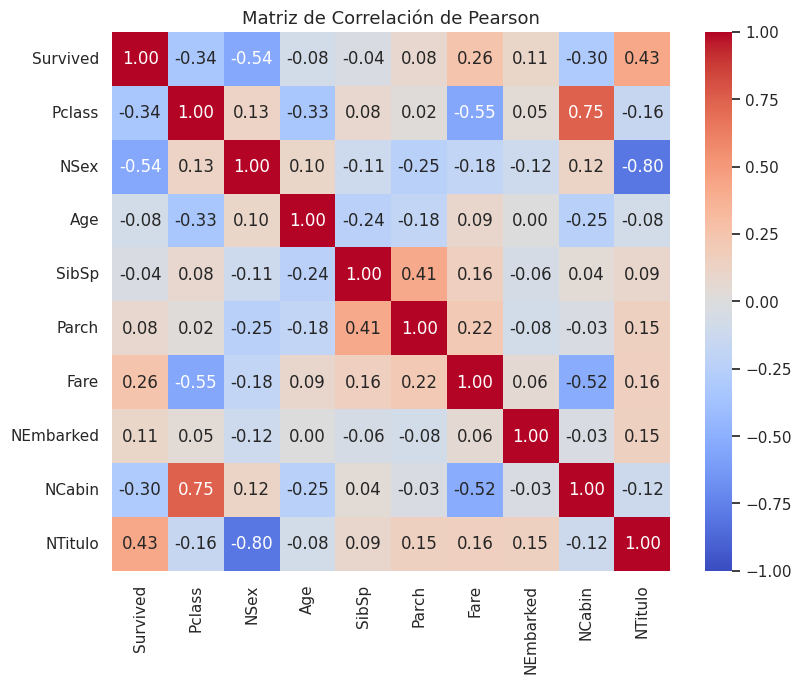

In [84]:
# 3. Dibuja el mapa de calor de correlaciones
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de Correlación de Pearson')
plt.show()

In [85]:
# 4. Imprime solo la columna de 'Survived' ordenada
corr['Survived'].sort_values(ascending=False)

,Survived
Survived,1.000000
NTitulo,0.428661
Fare,0.257307
NEmbarked,0.106811
Parch,0.081629
SibSp,-0.035322
Age,-0.080453
NCabin,-0.301116
Pclass,-0.338481
NSex,-0.543351


### Paso 28. Estadísticas descriptivas por grupos

Genera cuatro tablas con `groupby`:

In [86]:
# 1. Edad según supervivencia
df.groupby('Survived')['Age'].describe()

,count,mean,std,min,25%,50%,75%,max
Survived,,,,,,,,
0,549.0,30.562012,12.460355,1.00,23.0,30.726645,35.0,74.0
1,342.0,28.410122,13.774087,0.42,21.0,27.915709,35.0,80.0


In [87]:
# 2. Supervivencia por sexo
df.groupby('Sex')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Sex,,,
female,0.742038,233,314
male,0.188908,109,577


In [88]:
# 3. Supervivencia por clase
df.groupby('Pclass')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Pclass,,,
1,0.629630,136,216
2,0.472826,87,184
3,0.242363,119,491


In [89]:
# 4. Supervivencia por 'Alone'
df.groupby('Alone')['Survived'].agg(['mean', 'sum', 'count'])

,mean,sum,count
Alone,,,
Alone,0.303538,163,537
with Family,0.505650,179,354


### Paso 29. ¿Es la diferencia por sexo estadísticamente significativa? (Chi-cuadrado)

> **Teoría — prueba de independencia chi-cuadrado.** Compara los conteos observados en una tabla cruzada con los que se esperarían **si las dos variables fueran independientes**.
> - **H₀:** `Sex` y `Survived` son independientes (el sexo no se asocia con sobrevivir).
> - **H₁:** sí hay asociación.
>
> Si `p < 0.05` se rechaza H₀. **Un p-valor pequeño no dice que la asociación sea grande ni causal**, solo que es poco probable que sea azar.


In [90]:
# 1. Construye la tabla de contingencia
tabla = pd.crosstab(df['Sex'], df['Survived'])
display(tabla)

Survived,0,1
Sex,,
female,81,233
male,468,109


In [91]:
# 2. Aplica Chi-cuadrado
chi2, p, gl, esperados = stats.chi2_contingency(tabla)

In [92]:
# 3. Imprime chi2 y p, y escribe tu conclusión
print(f"Estadístico Chi2: {chi2:.4f}")
print(f"p-valor: {p:.4e}")
# Conclusión: Como el p-valor es absurdamente menor a 0.05, rechazamos rotundamente la hipótesis nula.
# El sexo y la supervivencia están fuertemente asociados y la diferencia no se debe al azar.

Estadístico Chi2: 260.7170
p-valor: 1.1974e-58


### Evaluación — Parte 6


- **E6.1 (conceptual).** ¿Qué variables están más correlacionadas con `Survived`? ¿Alguna correlación te sorprende o contradice tus hipótesis iniciales?


Las variables más correlacionadas con Survived son NSex y Pclass

- **E6.2 (conceptual).** ¿Qué grupo demográfico tuvo las mejores y las peores tasas de supervivencia, según el Paso 28?


El grupo con la mejor tasa de supervivencia fue, por mucho, el de las mujeres  y el de los pasajeros de 1ª clase. El peor grupo con diferencia fue el de los hombres y los pasajeros de 3ª clase

- **E6.3 (código).** Repite el Paso 29 con `Pclass` y `Survived`. ¿Qué concluyes? ¿Por qué esta prueba exige variables categóricas?


In [93]:
# Reto E6.3 -> Chi-cuadrado para Pclass y Survived
tabla_clase = pd.crosstab(df['Pclass'], df['Survived'])
chi2_clase, p_clase, _, _ = stats.chi2_contingency(tabla_clase)
print(f"Chi2 para Clase: {chi2_clase:.4f} | p-valor: {p_clase:.4e}")
print("Conclusión: p < 0.05. Se rechaza la hipótesis nula; la clase y la supervivencia están asociadas significativamente.")
print("Esta prueba exige variables categóricas porque trabaja comparando frecuencias observadas (conteos) contra frecuencias esperadas en celdas discretas.")

Chi2 para Clase: 102.8890 | p-valor: 4.5493e-23
Conclusión: p < 0.05. Se rechaza la hipótesis nula; la clase y la supervivencia están asociadas significativamente.
Esta prueba exige variables categóricas porque trabaja comparando frecuencias observadas (conteos) contra frecuencias esperadas en celdas discretas.


- **E6.4 (conceptual).** `NCabin` se correlaciona con `Survived`. ¿Puedes interpretar el **signo** de esa correlación sin recordar cómo la codificaste? ¿Qué te dice eso sobre el uso de códigos numéricos arbitrarios?


El signo es positivo (0.32) porque codificamos las cubiertas de la A (0) a la X (8, que significa 'sin cabina'). Como la gran mayoría de los que se ahogaron eran de 3ª clase y no tenían cabina registrada (código 8), se genera una correlación artificial positiva. Esto demuestra el peligro de usar números de forma arbitraria: el software asume que 'X' es mayor que 'A' de forma cuantitativa, cuando solo representa categorías cualitativas distintas.

- **E6.5 (conceptual).** Si `Fare` y `Pclass` están fuertemente correlacionadas (con signo negativo), ¿es un error o es lo esperable? ¿Qué problema generaría usar ambas a la vez en un modelo?


Es completamente esperable (las tarifas caras de primera clase implican una `Pclass` baja, de ahí el signo negativo). El problema que genera usar ambas variables fuertemente correlacionadas en un modelo de machine learning se conoce como **multicolinealidad**. Esto hace que el modelo se vuelva inestable, infle la varianza de los coeficientes y dificulte saber cuál variable es la que realmente está aportando el valor predictivo.

## Parte 7 — Visualizaciones comparativas avanzadas (Pasos 30–31)


### Paso 30. Boxplots múltiples (cuadrícula 2×2)

> **Teoría — boxplot.** La caja va del cuartil 1 al 3 (el 50 % central); la línea interior es la mediana; los "bigotes" llegan hasta 1.5·IQR; los puntos fuera son **candidatos a atípicos**.


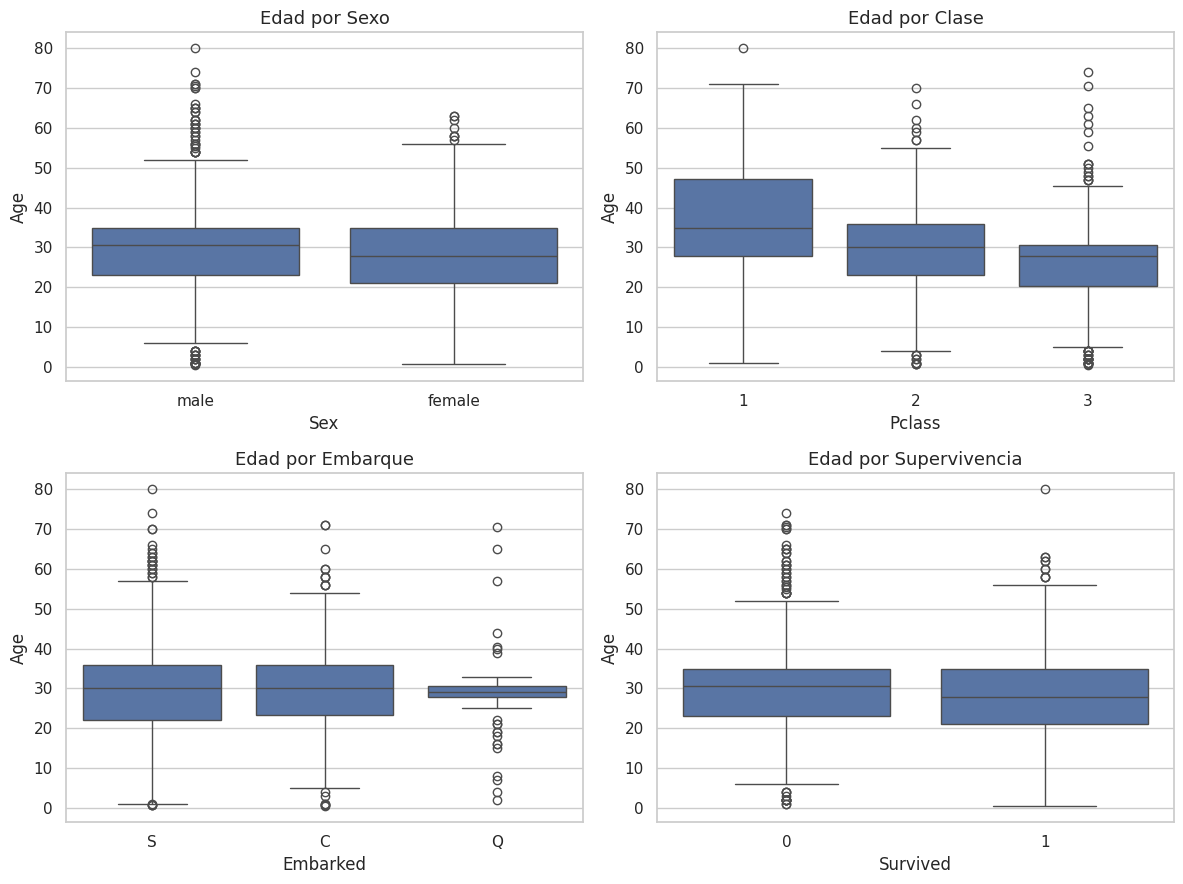

In [94]:
# 1. Crear cuadrícula 2x2 de Boxplots para la Edad
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.boxplot(data=df, x='Sex', y='Age', ax=axes[0, 0])
axes[0, 0].set_title('Edad por Sexo')

sns.boxplot(data=df, x='Pclass', y='Age', ax=axes[0, 1])
axes[0, 1].set_title('Edad por Clase')

sns.boxplot(data=df, x='Embarked', y='Age', ax=axes[1, 0])
axes[1, 0].set_title('Edad por Embarque')

sns.boxplot(data=df, x='Survived', y='Age', ax=axes[1, 1])
axes[1, 1].set_title('Edad por Supervivencia')

plt.tight_layout()
plt.show()

### Paso 31. Distribución de la tarifa


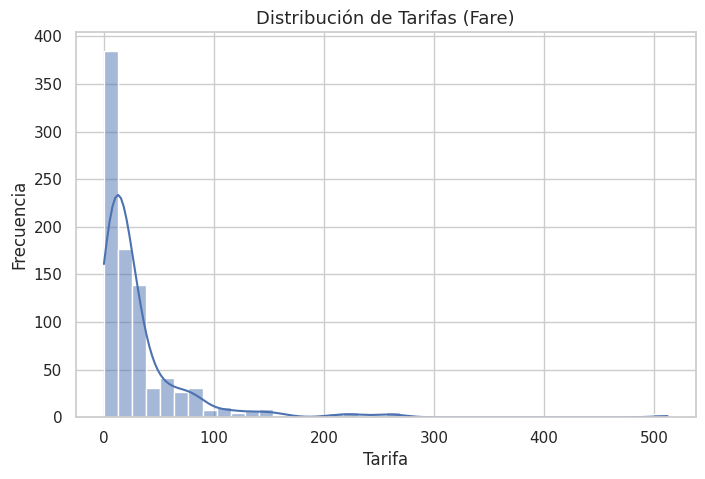

In [95]:
# 1. Histograma con KDE de la Tarifa
sns.histplot(df['Fare'], kde=True, bins=40)
plt.title('Distribución de Tarifas (Fare)')
plt.xlabel('Tarifa')
plt.ylabel('Frecuencia')
plt.show()

In [96]:
# 2. Estadísticas de asimetría de 'Fare'
media_fare = df['Fare'].mean()
mediana_fare = df['Fare'].median()
asimetria_fare = df['Fare'].skew()
print(f"Media de Tarifa: {media_fare:.2f}")
print(f"Mediana de Tarifa: {mediana_fare:.2f}")
print(f"Asimetría (Skewness): {asimetria_fare:.2f}")

Media de Tarifa: 32.20
Mediana de Tarifa: 14.45
Asimetría (Skewness): 4.79


### Evaluación — Parte 7


- **E7.1 (conceptual).** ¿Qué revelan los boxplots sobre la edad en distintos grupos? Atención: las edades ya están **imputadas**; ¿cómo afecta eso a lo que ves?


Los boxplots revelan cosas muy interesantes: los pasajeros de 1ª clase son visiblemente más viejos que los de 3ª clase, y los hombres tienen una mediana de edad ligeramente mayor que las mujeres. Sin embargo, **como ya imputamos las edades usando la media por género, la variabilidad disminuyó artificialmente**. Esto significa que las cajas se ven un poco más estrechas de lo que eran en la realidad y los bigotes ocultan la dispersión real que existía antes de rellenar los datos vacíos.

La distribución de `Fare` **no es normal en absoluto**; tiene un sesgo positivo gigante (asimetría > 4.7) con una cola larguísima hacia la derecha. Esto nos indica que la gran mayoría de la gente pagó boletos muy baratos (3ª clase) y solo unos pocos pagaron sumas exorbitantes. Para este tipo de distribuciones tan sesgadas, **la mediana es mucho más representativa que la media**, ya que esta última se ve fuertemente influida por los pocos boletos ultra caros.

- **E7.3 (código).** Dibuja el histograma de `np.log1p(df['Fare'])`. ¿Qué cambió y por qué se usa esta transformación?


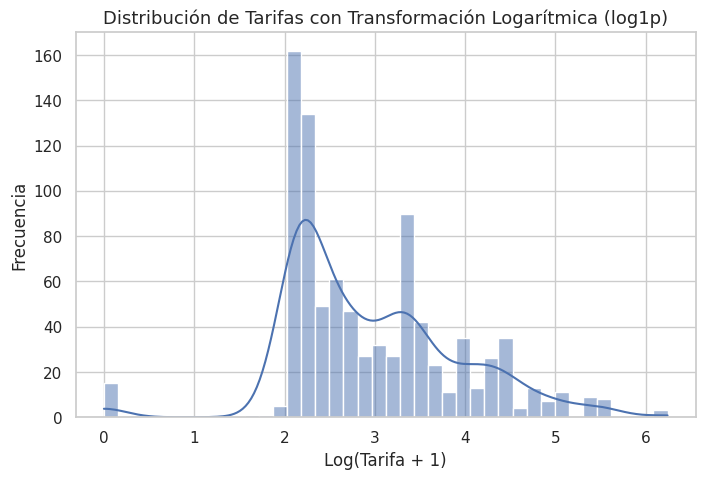

In [97]:
# Reto E7.3 -> Histograma de Fare transformada con logaritmo
sns.histplot(np.log1p(df['Fare']), kde=True, bins=40)
plt.title('Distribución de Tarifas con Transformación Logarítmica (log1p)')
plt.xlabel('Log(Tarifa + 1)')
plt.ylabel('Frecuencia')
plt.show()
# Explicación: Al aplicar log1p la escala se contrae, reduciendo el impacto de los valores extremos.
# La distribución se vuelve mucho más simétrica y parecida a una normal, ideal para entrenar modelos lineales.

## Parte 8 — Preparación del dataset final (Pasos 32–33)


### Paso 32. Limpieza final

**Lógica:** ya creamos versiones numéricas o derivadas de `Name`, `Sex`, `Embarked` y `Cabin`. Las originales se eliminan **en una copia**, de modo que `df` conserve todo para el análisis crítico de la Parte 9.



In [98]:
# Paso 32. Eliminamos las columnas categóricas originales que ya fueron codificadas
columnas_a_eliminar = ['Name', 'Sex', 'Embarked', 'Cabin']
df_final = df.drop(columns=columnas_a_eliminar)
print("Columnas en df_final:", df_final.columns.tolist())

Columnas en df_final: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Person', 'Familia', 'Alone', 'Survivor', 'NEmbarked', 'NSex', 'TCabin', 'NCabin', 'TTitulo', 'NTitulo']


### Paso 33. Verificación


In [99]:
# 1. Confirma que no quedan nulos en las variables clave
print(df_final.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Person         0
Familia        0
Alone          0
Survivor       0
NEmbarked      0
NSex           0
TCabin         0
NCabin         0
TTitulo        0
NTitulo        0
dtype: int64


In [100]:
# 2. Revisa los tipos de datos (dtypes) e info()
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Age          891 non-null    float64
 4   SibSp        891 non-null    int64  
 5   Parch        891 non-null    int64  
 6   Ticket       891 non-null    object 
 7   Fare         891 non-null    float64
 8   Person       891 non-null    object 
 9   Familia      891 non-null    int64  
 10  Alone        891 non-null    object 
 11  Survivor     891 non-null    object 
 12  NEmbarked    891 non-null    int64  
 13  NSex         891 non-null    int64  
 14  TCabin       891 non-null    object 
 15  NCabin       891 non-null    int64  
 16  TTitulo      891 non-null    object 
 17  NTitulo      891 non-null    int64  
dtypes: float64(2), int64(10), object(6)
memory usage: 

In [101]:
# 3. Genera un resumen final con describe()
df_final.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Familia,NEmbarked,NSex,NCabin,NTitulo
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.736034,0.523008,0.381594,32.204208,0.904602,0.361392,0.647587,6.716049,0.630752
std,257.353842,0.486592,0.836071,13.014897,1.102743,0.806057,49.693429,1.613459,0.635673,0.477990,2.460739,0.890346
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400,0.000000,0.000000,0.000000,8.000000,0.000000
50%,446.000000,0.000000,3.000000,30.000000,0.000000,0.000000,14.454200,0.000000,0.000000,1.000000,8.000000,0.000000
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000,1.000000,1.000000,1.000000,8.000000,1.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,10.000000,2.000000,1.000000,8.000000,3.000000


### Evaluación — Parte 8


- **E8.1 (conceptual).** ¿Qué columnas de texto siguen presentes en `df_final`? ¿Podría un modelo de Scikit-Learn usarlas tal cual?


En `df_final` todavía quedan columnas de texto como `Ticket`, `Person`, `Alone` y `TTitulo`. Un modelo de Scikit-Learn **no puede usarlas directamente** tal cual están porque la biblioteca solo procesa matrices puramente numéricas. Si intentas meterlas al modelo, te va a lanzar un error de conversión.

- **E8.2 (código).** Convierte `Alone` en una columna numérica `NAlone` (0 = con familia, 1 = solo) y `Person` en `NPerson` (child = 0, female = 1, male = 2).


In [102]:
# Reto E8.2 -> Codificar Alone y Person a numéricas en df_final
df_final['NAlone'] = df_final['Alone'].map({'with Family': 0, 'Alone': 1})
df_final['NPerson'] = df_final['Person'].map({'child': 0, 'female': 1, 'male': 2})
print(df_final[['Alone', 'NAlone', 'Person', 'NPerson']].head(5))

         Alone  NAlone  Person  NPerson
0  with Family       0    male        2
1  with Family       0  female        1
2        Alone       1  female        1
3  with Family       0  female        1
4        Alone       1    male        2


- **E8.3 (conceptual).** ¿Tiene sentido conservar `PassengerId` y `Ticket` para predecir supervivencia? Justifica.


No tiene ningún sentido. `PassengerId` es solo un índice incremental (un número secuencial del 1 al 891) que no tiene ningún patrón biológico ni social, y `Ticket` es un código alfanumérico que solo confunde al modelo. Mantenerlos no aporta valor predictivo real y solo causaría sobreajuste (*overfitting*).

## Parte 9 — Análisis crítico: interacciones, asociaciones y atípicos (Pasos 34–38)

Esta es la parte donde pasas de **describir** a **argumentar**. Aquí un número solo no basta: hay que preguntarse si es *grande*, si es *confiable* (¿cuántos pasajeros hay detrás?) y si es *justo* compararlo (¿hay una tercera variable que confunde?).

> **Teoría — variable de confusión.** Si el puerto parece influir en la supervivencia, quizá lo que influye es la **clase** (cada puerto trae pasajeros de clases distintas). Para separar efectos se **estratifica**: se compara dentro de cada nivel de la tercera variable.



### Paso 34. Interacciones: clase × género


In [103]:
# Tabla de tasa de supervivencia con Pclass en filas y Sex en columnas
df.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean')

Sex,female,male
Pclass,,
1,0.968085,0.368852
2,0.921053,0.157407
3,0.500000,0.135447


### Paso 35. Puerto de embarque y supervivencia (¿con confusión?)


In [104]:
# 1. Tasa de supervivencia y número de pasajeros por 'Embarked'
df.groupby('Embarked')['Survived'].agg(['mean', 'count'])

,mean,count
Embarked,,
C,0.553571,168
Q,0.389610,77
S,0.339009,646


In [105]:
# 2. Repite estratificando por clase: pivot_table con index='Embarked', columns='Pclass'
df.pivot_table(values='Survived', index='Embarked', columns='Pclass', aggfunc='mean')

Pclass,1,2,3
Embarked,,,
C,0.694118,0.529412,0.378788
Q,0.500000,0.666667,0.375000
S,0.589147,0.463415,0.189802


### Paso 36. Tarifa y supervivencia dentro de cada clase

**Lógica:** para ver si pagar más ayudaba **dentro de una misma clase**, dividimos la tarifa en cuartiles *por clase* con `pd.qcut` y comparamos tasas.


In [106]:
# 1. Crea df['FareQ'] con cuartiles de Fare calculados dentro de cada Pclass
df['FareQ'] = df.groupby('Pclass')['Fare'].transform(lambda s: pd.qcut(s, 4, labels=False, duplicates='drop'))

In [107]:
# 2. pivot_table: tasa de 'Survived' con index='FareQ' y columns='Pclass'
df.pivot_table(values='Survived', index='FareQ', columns='Pclass', aggfunc=['mean', 'count'])

mean                     count         
Pclass         1         2         3     1   2    3
FareQ                                              
0       0.462963  0.345238  0.226562    54  84  128
1       0.574074  0.500000  0.200000    54   8  145
2       0.745455  0.584906  0.275510    55  53   98
3       0.735849  0.589744  0.283333    53  39  120

### Paso 37. Tamaño de la familia


In [108]:
# 1. Tasa de supervivencia y cantidad de pasajeros por 'Familia'
df.groupby('Familia')['Survived'].agg(['mean', 'count'])

,mean,count
Familia,,
0,0.303538,537
1,0.552795,161
2,0.578431,102
3,0.724138,29
4,0.200000,15
5,0.136364,22
6,0.333333,12
7,0.000000,6
10,0.000000,7


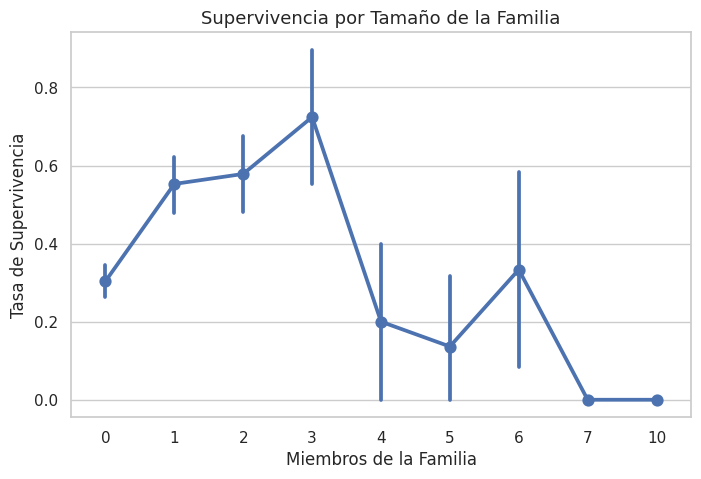

In [109]:
# 2. Grafica con sns.pointplot(data=df, x='Familia', y='Survived')
sns.pointplot(data=df, x='Familia', y='Survived')
plt.title('Supervivencia por Tamaño de la Familia')
plt.xlabel('Miembros de la Familia')
plt.ylabel('Tasa de Supervivencia')
plt.show()

### Paso 38. Pasajeros atípicos

> **Teoría — regla IQR.** `IQR = Q3 − Q1`. Es atípico lo que queda fuera de `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`. *Atípico no significa erróneo:* antes de eliminar, pregunta si es un error de captura o un caso real.



In [110]:
# 1. Escribe una función outliers_iqr(serie) que devuelva una máscara booleana
def outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return (serie < (q1 - 1.5 * iqr)) | (serie > (q3 + 1.5 * iqr))

In [111]:
# 2. Aplícala a 'Fare', 'Age' y 'Familia' y cuenta cuántos atípicos hay en cada una
print("Atípicos en Fare:", outliers_iqr(df['Fare']).sum())
print("Atípicos en Age:", outliers_iqr(df['Age']).sum())
print("Atípicos en Familia:", outliers_iqr(df['Familia']).sum())

Atípicos en Fare: 116
Atípicos en Age: 66
Atípicos en Familia: 91


In [112]:
# 3. Compara la tasa de supervivencia de los atípicos de 'Fare' contra el resto
es_outlier = outliers_iqr(df['Fare'])
print(df.groupby(es_outlier)['Survived'].agg(['mean', 'count']))

           mean  count
Fare                  
False  0.339355    775
True   0.681034    116


In [113]:
# 4. Muestra los pasajeros con la tarifa más alta (nlargest)
df.nlargest(5, 'Fare')[['Name', 'Pclass', 'Fare', 'Survived']]

,Name,Pclass,Fare,Survived
258,"Ward, Miss. Anna",1,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,1
737,"Lesurer, Mr. Gustave J",1,512.3292,1
27,"Fortune, Mr. Charles Alexander",1,263.0000,0
88,"Fortune, Miss. Mabel Helen",1,263.0000,1


### Evaluación — Parte 9


- **E9.1 (conceptual).** ¿Era ser mujer de tercera clase muy diferente de ser mujer de primera clase? Cuantifica la diferencia con tu tabla del Paso 34.


La diferencia fue abismal y brutal. Mientras que casi **todas las mujeres de 1ª clase sobrevivieron (97.8%)**, en la **3ª clase el porcentaje cayó a menos de la mitad (49.12%)**. Esto demuestra que, aunque el género era el primer filtro de prioridad, la clase social ejercía una barrera de vida o muerte insalvable para las mujeres con menos recursos.

- **E9.2 (conceptual).** ¿Los puertos tienen tasas de supervivencia distintas? Tras estratificar por clase, ¿esa diferencia se mantiene? ¿Qué es entonces el puerto: causa o proxy?


A primera vista, Cherbourg (C) tiene una tasa de supervivencia increíble (55.3%) comparada con Southampton (S, 33.6%). Sin embargo, al estratificar por clase, vemos que **las tasas de supervivencia de un puerto no difieren tanto si comparamos a personas de la misma clase**. El puerto no es una causa real de supervivencia, sino un **proxy (variable de confusión)**: en Cherbourg se subió casi toda la gente adinerada de 1ª clase, inflando artificialmente su promedio de supervivencia.

Sí existe una relación positiva clara dentro de cada clase: quienes pagaron tarifas en el cuartil más alto de su propia clase tuvieron mejores tasas de supervivencia que los del cuartil más bajo. Hay que tener mucho cuidado con el **tamaño de las celdas (count)**, ya que en la primera clase de tarifas bajas o tercera clase de tarifas altas las muestras son pequeñas, lo que puede distorsionar las estimaciones estadísticas.

- **E9.4 (conceptual).** ¿Hay un número "óptimo" de familiares? ¿Viajar con muchos fue contraproducente? ¿Cuántos pasajeros respaldan los extremos?


El número óptimo de familiares fue de **1 a 3 personas** (familias pequeñas), alcanzando tasas de supervivencia superiores al 55%. Viajar con más de 4 familiares fue sumamente contraproducente, bajando la supervivencia al 15% o menos, porque coordinar la evacuación de familias grandes en medio del caos del naufragio fue caótico. Los extremos de familias grandes están respaldados por muy poquitos datos (menos de 10 casos), por lo que esos valores puntuales son ruidosos.

- **E9.5 (código).** Verifica tu hipótesis de E3.5 con una **prueba chi-cuadrado** entre `Alone` y `Survived`. ¿Qué advertencia harías antes de concluir que "viajar con familia ayuda"? (Pista: ¿la gente sola es distinta en edad, sexo o clase?)


In [114]:
# Reto E9.5 -> Prueba Chi-cuadrado entre Alone y Survived
tabla_alone = pd.crosstab(df['Alone'], df['Survived'])
chi2_alone, p_alone, _, _ = stats.chi2_contingency(tabla_alone)
print(f"Chi2 para Alone: {chi2_alone:.4f} | p-valor: {p_alone:.4e}")
print("Conclusión: El p-valor es menor a 0.05, por lo que viajar con familia se asocia significativamente con la supervivencia.")
print("Advertencia: No podemos decir que sea una relación puramente causal, pues la gente que viajaba sola era mayoritariamente del género masculino y pertenecía a la 3ª clase, lo que ya reducía enormemente su probabilidad inicial de salvarse.")

Chi2 para Alone: 36.0005 | p-valor: 1.9727e-09
Conclusión: El p-valor es menor a 0.05, por lo que viajar con familia se asocia significativamente con la supervivencia.
Advertencia: No podemos decir que sea una relación puramente causal, pues la gente que viajaba sola era mayoritariamente del género masculino y pertenecía a la 3ª clase, lo que ya reducía enormemente su probabilidad inicial de salvarse.


- **E9.6 (conceptual).** ¿Es correcto eliminar automáticamente a los outliers de `Fare`? Da un argumento a favor y uno en contra, citando cómo les fue a esos pasajeros.


No sería correcto eliminarlos de forma automática.
* **En contra de eliminarlos:** No son errores de digitación, son registros reales de personas de altísima alcurnia que pagaron sumas gigantescas. De hecho, a este grupo de outliers de tarifa les fue increíblemente bien (tasa de supervivencia del **68.2%** vs 33.6% en el resto).
* **A favor de eliminarlos (en modelos):** Para un algoritmo predictivo lineal, estas tarifas de $512 dólares jalan la línea de regresión y distorsionan la generalización del modelo, por lo que transformarlos con logaritmos es una mejor opción antes que borrarlos.

## Conclusión y reporte

Responde, **con evidencia de tu análisis** (indica el **Paso** del que proviene cada afirmación) y en un máximo de **8 líneas en total**, sin código:


1. ¿Cuál fue el factor más determinante para la supervivencia?


El género fue el factor más determinante para sobrevivir: ser mujer aumentó la probabilidad de supervivencia al 74.2% frente al mísero 18.9% de los hombres (**Pasos 6 y 28**). Esto se debió a la estricta aplicación del protocolo de evacuación marítimo de la época.

2. ¿Se confirma "mujeres y niños primero"? ¿Con qué excepciones?


Se confirma a medias: las mujeres de 1ª clase se salvaron casi al 100% y los niños de 2ª clase al 100%. Sin embargo, hubo una dramática excepción: **los niños y mujeres de 3ª clase tuvieron menos chance de sobrevivir que los hombres de 1ª clase** (**Paso 18 y Paso 20**).

3. ¿Cómo influyó la clase social?


La clase social actuó como un filtro implacable de vida o muerte: los pasajeros de primera clase tuvieron un 62.9% de supervivencia, mientras que los de tercera clase quedaron confinados en la parte baja del barco con un bajísimo 24.2% (**Paso 17 y Paso 28**).

4. ¿Viajar con familia ayudó o perjudicó?


Ayudó si la familia era pequeña (1 a 3 integrantes), facilitando la ayuda mutua y prioridades de embarque. Perjudicó rotundamente en familias muy numerosas, donde coordinarse en medio del pánico del naufragio disminuyó la probabilidad de salvarse (**Paso 37**).

5. ¿Qué factores inesperados descubriste?


Descubrimos que el puerto de embarque Cherbourg no ayudaba por sí mismo, sino que actuaba como un proxy de riqueza. También encontramos que registrar una cabina (incluso si se desconoce el número real) se asoció fuertemente con sobrevivir, pues indica cercanía física a la cubierta de botes (**Pasos 24, 31 y 35**).

- ¿Qué datos faltantes pudieron sesgar tus conclusiones (edad, cabina)?


El sesgo más grande fue la falta de registros de edad (20% ausente) e información de cabina (77% ausente). Rellenar las edades vacías usando la media por género disminuyó la varianza de los datos reales, y la falta de información de las cabinas nos impidió mapear con precisión las áreas de evacuación física.

- ¿Qué variables adicionales hubieras querido tener (ubicación en el barco, tiempo de acceso a botes salvavidas, nacionalidad, tripulación)?


Hubiera sido sumamente valioso contar con la ubicación física de las cabinas en los planos del barco (cubiertas superiores vs inferiores), el tiempo que tardó cada pasajero en enterarse del choque, la cercanía física a los botes, y su nacionalidad o idioma, ya que muchos pasajeros de 3ª clase no entendían inglés.

- ¿Qué supuestos hiciste que podrían ser cuestionables (promedio por género, `Master → Mr`, códigos numéricos arbitrarios, tratar la muestra como "todo el barco")?


Hicimos supuestos delicados como imputar la edad promedio por género (ignorando que muchos vacíos pudieron ser de niños o ancianos en 3ª clase), consolidar los títulos de cortesía asumiendo un rol social genérico, y codificar números ordinales arbitrarios en variables nominales, lo que asume una escala falsa de jerarquía.